# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project. 

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset. 


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [2]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from utils import TODO


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [5]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = './'
DATASET = 'C16'  # Choose: 'C16', 'C17', or 'BRACS'

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}
CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


Project: c:\U of T courses\CS courses\ECE1512\ProjectA
Config : ./config\camelyon16_medical_ssl_config.yml


In [6]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/C16/patch_feats_pretrain_medical_ssl.h5', dataset='CAMELYON16', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=2, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, val_fraction=0.1, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/C16/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [5]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 242, Validation 27, Test 129;
Feature Shape: (4332, 384);
Label: 0; 
Slide ID: normal_028.


In [6]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory True;  
       collate_fn <function mil_collate_fn at 0x000001F9B83B7240>


In [7]:
# TODO 1A: create the training DataLoader. Training data should be shuffled.
train_loader = DataLoader(
    dataset=train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    collate_fn=collate_fn
)

# TODO 1B: create validation and test DataLoaders. Do not shuffle them.
val_loader = DataLoader(
    dataset=val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    collate_fn=collate_fn)
test_loader = DataLoader(
    dataset=test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    collate_fn=collate_fn)


In [8]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 12367, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['tumor_010']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [8]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # TODO 2A: one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # TODO 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # TODO 2C: project patch features to m_dim and use ReLU.
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # TODO 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # TODO 2E: implement the two gated branches.
        a_v = self.attention_V(x)
        a_u = self.attention_U(x)

        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)             


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, return_attention=False):
        # x: [B, N, D_feat]
        med_feat = self.dimreduction(x)       # [B, N, D_inner]
        a_logits = self.attention(med_feat)   # [B, 1, N]


        # TODO 2G: normalize attention logits over the instance dimension.
        attention = F.softmax(a_logits, dim=-1)
        
        # TODO 2H: weighted aggregation. torch.bmm is useful here.
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)

        # TODO 2I: classify the slide representation.
        logits = self.classifier(bag_feat)

        if return_attention:
            return logits, attention
        return logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [10]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 2])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.],
        [1.]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# TODO 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# TODO 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr=conf.lr, weight_decay=conf.wd)

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cuda
Trainable parameters: 164995


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [12]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # TODO 4A: put the model in training mode.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # TODO 4B: move input and labels to the selected device.
        bag = data["input"].to(device, dtype=torch.float32)
        labels = data["label"].to(device, dtype=torch.long)

        # TODO 4C: clear gradients from the previous iteration.
        optimizer.zero_grad()

        # TODO 4D: forward pass.
        logits = model(bag)

        # TODO 4E: compute the loss.
        loss = criterion(logits, labels)

        # TODO 4F: back-propagate gradients.
        loss.backward()

        # TODO 4G: update the model parameters.
        optimizer.step()

        batch_size = labels.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }


# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [13]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # TODO 5A: switch to evaluation mode.
    model.eval()

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # TODO 5B: move data to device.
        bag = data["input"].to(device, dtype=torch.float32)
        labels = data["label"].to(device, dtype=torch.long)

        # TODO 5C: forward pass and loss.
        logits = model(bag)
        loss = criterion(logits, labels)

        # TODO 5D: convert class logits into probabilities.
        probabilities = F.softmax(logits, dim=1)

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [14]:
NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Baseline selection criterion: macro-AUROC + macro-F1.
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None


Epoch 01/30 | train loss=0.6759 acc=57.85 | val loss=0.5061 auc=0.892 f1=0.785 | best=1 | 9.2s
Epoch 02/30 | train loss=0.4500 acc=78.51 | val loss=0.1814 auc=1.000 f1=1.000 | best=2 | 7.1s
Epoch 03/30 | train loss=0.2325 acc=91.74 | val loss=0.0932 auc=1.000 f1=1.000 | best=2 | 6.9s
Epoch 04/30 | train loss=0.1601 acc=95.45 | val loss=0.0197 auc=1.000 f1=1.000 | best=2 | 6.6s
Epoch 05/30 | train loss=0.1306 acc=95.87 | val loss=0.0101 auc=1.000 f1=1.000 | best=2 | 6.0s
Epoch 06/30 | train loss=0.1053 acc=96.28 | val loss=0.0111 auc=1.000 f1=1.000 | best=2 | 6.0s
Epoch 07/30 | train loss=0.0849 acc=97.11 | val loss=0.0112 auc=1.000 f1=1.000 | best=2 | 6.1s
Epoch 08/30 | train loss=0.0537 acc=98.35 | val loss=0.0046 auc=1.000 f1=1.000 | best=2 | 6.0s
Epoch 09/30 | train loss=0.0432 acc=98.76 | val loss=0.0026 auc=1.000 f1=1.000 | best=2 | 6.0s
Epoch 10/30 | train loss=0.0454 acc=98.35 | val loss=0.0019 auc=1.000 f1=1.000 | best=2 | 6.1s
Epoch 11/30 | train loss=0.0225 acc=99.17 | val lo

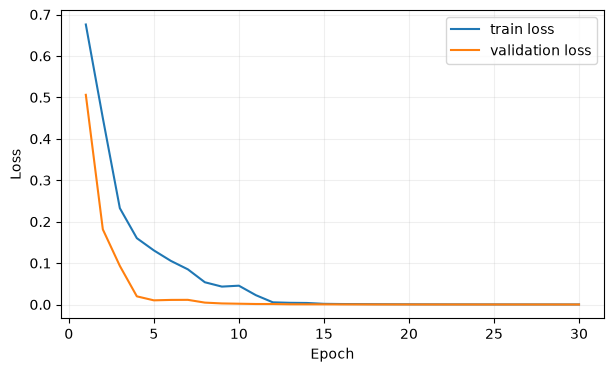

In [15]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.savefig(f'loss_{DATASET}.png', dpi=200, bbox_inches='tight')
plt.show()

# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [16]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')


Best validation epoch: 2
Final test metrics:
  auc: 0.8704
  acc: 82.9457
  f1: 0.8159
  loss: 0.4165


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [17]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))


Slide: test_001
Predicted class: 1
Attention shape: (1, 1, 17294)
Attention sum for first slide: 1.0000001192092896


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


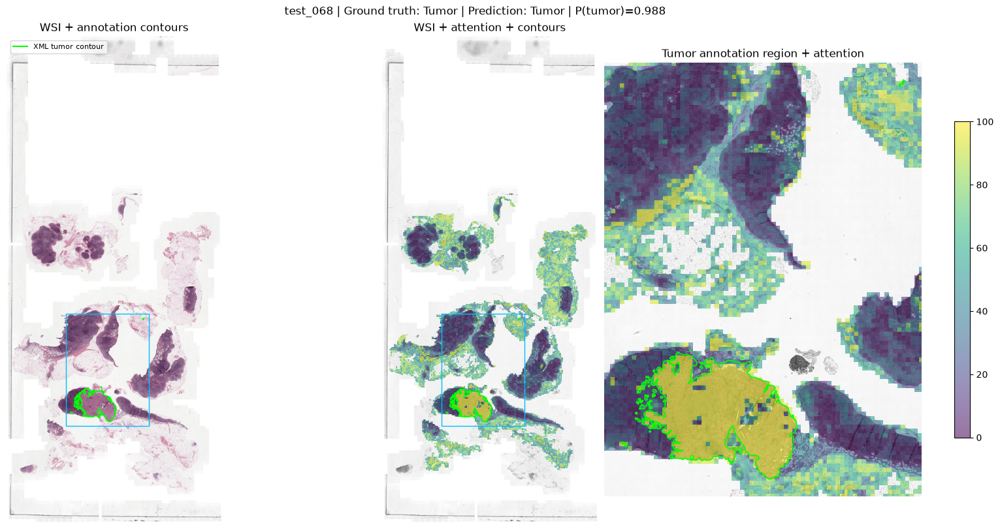

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


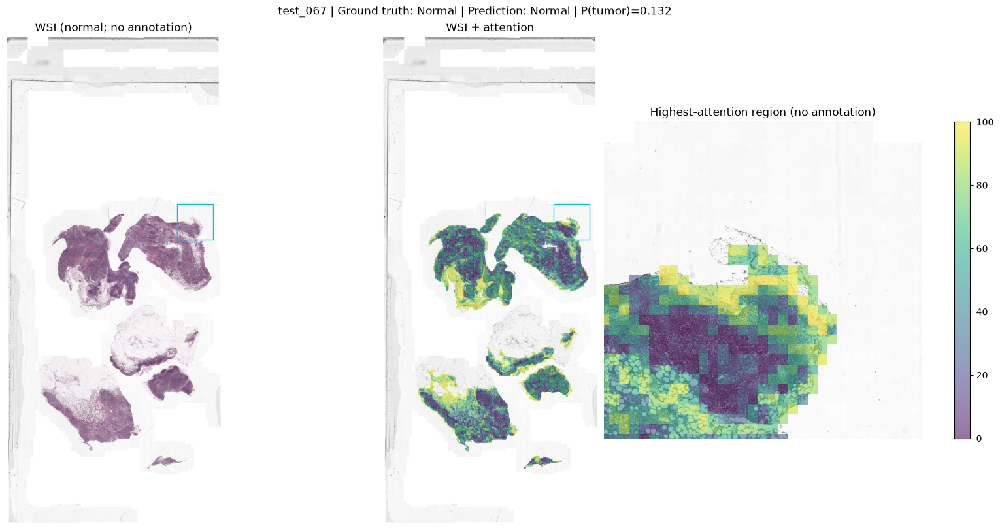

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)


In [18]:
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)


# Step 8b - Run all datasets with several seeds

Steps 1-7 train one model on one dataset. The cells below repeat that pipeline for **C16, C17 and BRACS**, each with seeds **42, 0 and 1**, then report test mean ± std (course notes §6.6). They reuse `ABMIL`, `train_one_epoch` and `evaluate` from above, so run Steps 0-5 first.

- The **train/validation/test split is the same for every seed**. It comes from `seed` in each YAML file (42). The run seed only changes weight initialisation and training-set shuffling, so the spread across seeds is training noise, not a different split.
- Every run writes `results/{DATASET}_seed{SEED}.json` (history + test metrics), `results/{DATASET}_seed{SEED}_test_predictions.csv` (per-slide probabilities, for confusion matrices and error analysis) and `results/ckpt/{DATASET}_seed{SEED}.pt` (best checkpoint).
- Runs that already have a JSON file are skipped, so if the kernel dies you can rerun the cell and it picks up where it stopped. Set `RERUN = True` to train everything again.

In [16]:
import json
import pandas as pd

RESULTS_DIR = Path(PROJECT_DIR) / 'results'
FIG_DIR = RESULTS_DIR / 'figures'
CKPT_DIR = RESULTS_DIR / 'ckpt'
for d in (RESULTS_DIR, FIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)


def build_loaders(conf):
    train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
    conf.D_feat = infer_feature_dim(train_data)
    loader_kwargs = dict(
        batch_size=conf.B,
        num_workers=int(conf.n_worker),
        pin_memory=bool(conf.pin_memory) and torch.cuda.is_available(),
        collate_fn=mil_collate_fn,
    )
    print(f'{conf.dataset}: Train {len(train_data)}, Validation {len(val_data)}, Test {len(test_data)}')
    return (DataLoader(train_data, shuffle=True, **loader_kwargs),
            DataLoader(val_data, shuffle=False, **loader_kwargs),
            DataLoader(test_data, shuffle=False, **loader_kwargs))


@torch.no_grad()
def predict_slides(model, data_loader, device):
    model.eval()
    rows = []
    for data in data_loader:
        probabilities = F.softmax(model(data['input'].to(device, dtype=torch.float32)), dim=1).cpu()
        for slide_id, label, p in zip(data['slide_id'], data['label'].tolist(), probabilities):
            row = {'slide_id': slide_id, 'label': int(label), 'pred': int(p.argmax())}
            row.update({f'prob_{c}': float(v) for c, v in enumerate(p)})
            rows.append(row)
    return pd.DataFrame(rows)


def plot_loss(history, title, path):
    epochs = [x['epoch'] + 1 for x in history]
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
    plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.close()


def run_experiment(dataset, seed, conf, loaders, num_epochs=None):
    train_loader, val_loader, test_loader = loaders
    seed_everything(seed)  # weight init and training-set shuffling
    model = ABMIL(conf).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=conf.lr, weight_decay=conf.wd)
    num_epochs = num_epochs or int(conf.train_epoch)

    best_score, best_epoch, best_model_state, history = float('-inf'), -1, None, []
    for epoch in range(num_epochs):
        start = time.time()
        train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
        val_metrics = evaluate(model, criterion, val_loader, device, conf)
        score = val_metrics['auc'] + val_metrics['f1']
        if score > best_score:
            best_score, best_epoch = score, epoch
            best_model_state = copy.deepcopy(model.state_dict())
        row = {
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'train_acc': train_metrics['acc'],
            'val_loss': val_metrics['loss'],
            'val_acc': val_metrics['acc'],
            'val_auc': val_metrics['auc'],
            'val_f1': val_metrics['f1'],
        }
        history.append(row)
        print(f"[{dataset} seed {seed}] Epoch {epoch+1:02d}/{num_epochs} | "
              f"train loss={row['train_loss']:.4f} | val loss={row['val_loss']:.4f} "
              f"auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | best={best_epoch+1} | {time.time()-start:.1f}s")

    # Test set touched once, with the checkpoint chosen on validation.
    model.load_state_dict(best_model_state)
    test_metrics = evaluate(model, criterion, test_loader, device, conf)
    print(f'[{dataset} seed {seed}] best epoch {best_epoch+1} | test ' +
          ', '.join(f'{k}={v:.4f}' for k, v in test_metrics.items()))

    tag = f'{dataset}_seed{seed}'
    record = {
        'dataset': dataset,
        'seed': seed,
        'num_epochs': num_epochs,
        'best_epoch': best_epoch + 1,
        'history': history,
        'test_metrics': test_metrics,
    }
    (RESULTS_DIR / f'{tag}.json').write_text(json.dumps(record, indent=2))
    predict_slides(model, test_loader, device).to_csv(RESULTS_DIR / f'{tag}_test_predictions.csv', index=False)
    torch.save(best_model_state, CKPT_DIR / f'{tag}.pt')
    plot_loss(history, f'{dataset}, seed {seed}', FIG_DIR / f'loss_{tag}.png')
    return record


def plot_seed_curves(dataset, records):
    # One figure per dataset: train (solid) and validation (dashed) loss for every seed.
    plt.figure(figsize=(7, 4))
    for i, r in enumerate(records):
        epochs = [x['epoch'] + 1 for x in r['history']]
        plt.plot(epochs, [x['train_loss'] for x in r['history']], color=f'C{i}', label=f"train, seed {r['seed']}")
        plt.plot(epochs, [x['val_loss'] for x in r['history']], color=f'C{i}', linestyle='--', label=f"val, seed {r['seed']}")
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{dataset} learning curves')
    plt.legend(fontsize=8)
    plt.grid(alpha=0.2)
    plt.savefig(FIG_DIR / f'loss_{dataset}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [17]:
DATASETS = ['C16', 'C17', 'BRACS']
SEEDS = [42, 0, 1]
NUM_EPOCHS_ALL = None  # None uses train_epoch from each config; set 2 for a quick dry run.
RERUN = False          # True retrains runs that already have a results JSON.

CAMELYON16: Train 242, Validation 27, Test 129
[C16 seed 42] Epoch 01/30 | train loss=0.6744 | val loss=0.4984 auc=0.915 f1=0.750 | best=1 | 6.5s
[C16 seed 42] Epoch 02/30 | train loss=0.4493 | val loss=0.2187 auc=1.000 f1=0.921 | best=2 | 6.6s
[C16 seed 42] Epoch 03/30 | train loss=0.2323 | val loss=0.0499 auc=1.000 f1=1.000 | best=3 | 6.7s
[C16 seed 42] Epoch 04/30 | train loss=0.1495 | val loss=0.0218 auc=1.000 f1=1.000 | best=3 | 6.7s
[C16 seed 42] Epoch 05/30 | train loss=0.1034 | val loss=0.0172 auc=1.000 f1=1.000 | best=3 | 6.7s
[C16 seed 42] Epoch 06/30 | train loss=0.0709 | val loss=0.0053 auc=1.000 f1=1.000 | best=3 | 6.8s
[C16 seed 42] Epoch 07/30 | train loss=0.0675 | val loss=0.0061 auc=1.000 f1=1.000 | best=3 | 6.6s
[C16 seed 42] Epoch 08/30 | train loss=0.0317 | val loss=0.0037 auc=1.000 f1=1.000 | best=3 | 6.6s
[C16 seed 42] Epoch 09/30 | train loss=0.0290 | val loss=0.0032 auc=1.000 f1=1.000 | best=3 | 6.8s
[C16 seed 42] Epoch 10/30 | train loss=0.0152 | val loss=0.002

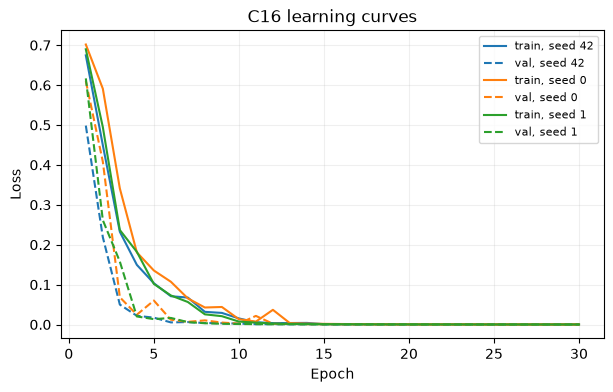

CAMELYON17: Train 269, Validation 30, Test 200
[C17 seed 42] Epoch 01/30 | train loss=1.0553 | val loss=1.0369 auc=0.508 f1=0.200 | best=1 | 13.1s
[C17 seed 42] Epoch 02/30 | train loss=0.9652 | val loss=1.0012 auc=0.561 f1=0.200 | best=2 | 11.2s
[C17 seed 42] Epoch 03/30 | train loss=0.7814 | val loss=0.6658 auc=0.805 f1=0.405 | best=3 | 10.9s
[C17 seed 42] Epoch 04/30 | train loss=0.5341 | val loss=0.5222 auc=0.881 f1=0.427 | best=4 | 11.1s
[C17 seed 42] Epoch 05/30 | train loss=0.4710 | val loss=0.4464 auc=0.892 f1=0.500 | best=5 | 11.5s
[C17 seed 42] Epoch 06/30 | train loss=0.3895 | val loss=0.4483 auc=0.877 f1=0.621 | best=6 | 11.6s
[C17 seed 42] Epoch 07/30 | train loss=0.3616 | val loss=0.4543 auc=0.875 f1=0.675 | best=7 | 10.8s
[C17 seed 42] Epoch 08/30 | train loss=0.3182 | val loss=0.4766 auc=0.870 f1=0.500 | best=7 | 9.4s
[C17 seed 42] Epoch 09/30 | train loss=0.2972 | val loss=0.4409 auc=0.864 f1=0.621 | best=7 | 11.3s
[C17 seed 42] Epoch 10/30 | train loss=0.2786 | val lo

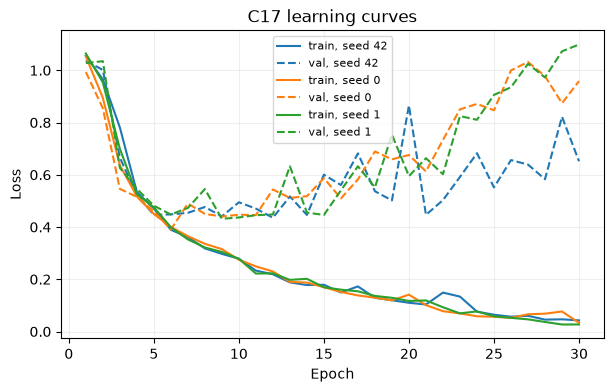

BRACS: Train 389, Validation 62, Test 86
[BRACS seed 42] Epoch 01/30 | train loss=1.6019 | val loss=1.8187 auc=0.683 f1=0.192 | best=1 | 19.8s
[BRACS seed 42] Epoch 02/30 | train loss=1.2425 | val loss=1.7573 auc=0.744 f1=0.134 | best=2 | 15.7s
[BRACS seed 42] Epoch 03/30 | train loss=1.0570 | val loss=1.4000 auc=0.807 f1=0.443 | best=3 | 15.4s
[BRACS seed 42] Epoch 04/30 | train loss=0.9259 | val loss=1.3702 auc=0.822 f1=0.361 | best=3 | 16.8s
[BRACS seed 42] Epoch 05/30 | train loss=0.8609 | val loss=1.4273 auc=0.822 f1=0.363 | best=3 | 16.9s
[BRACS seed 42] Epoch 06/30 | train loss=0.8018 | val loss=1.4914 auc=0.824 f1=0.346 | best=3 | 14.7s
[BRACS seed 42] Epoch 07/30 | train loss=0.7542 | val loss=1.5263 auc=0.828 f1=0.369 | best=3 | 13.9s
[BRACS seed 42] Epoch 08/30 | train loss=0.7198 | val loss=1.5490 auc=0.814 f1=0.338 | best=3 | 14.4s
[BRACS seed 42] Epoch 09/30 | train loss=0.6736 | val loss=1.5013 auc=0.815 f1=0.356 | best=3 | 15.9s
[BRACS seed 42] Epoch 10/30 | train loss=

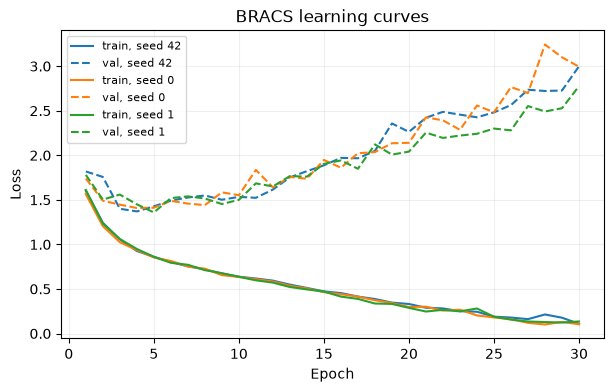

In [ ]:
all_runs = []
for ds in DATASETS:
    conf_ds = load_config(os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[ds]))
    loaders = build_loaders(conf_ds)  # split fixed by conf_ds.seed, shared by all run seeds
    ds_runs = []
    for seed in SEEDS:
        out = RESULTS_DIR / f'{ds}_seed{seed}.json'
        if out.exists() and not RERUN:
            print(f'[{ds} seed {seed}] found {out}, skipping')
            ds_runs.append(json.loads(out.read_text()))
            continue
        ds_runs.append(run_experiment(ds, seed, conf_ds, loaders, NUM_EPOCHS_ALL))
    plot_seed_curves(ds, ds_runs)
    all_runs.extend(ds_runs)

In [21]:
metric_names = ['auc', 'acc', 'f1', 'loss']
runs_df = pd.DataFrame([
    {'dataset': r['dataset'], 'seed': r['seed'], 'best_epoch': r['best_epoch'], **r['test_metrics']}
    for r in all_runs
])
runs_df.to_csv(RESULTS_DIR / 'test_metrics_all_runs.csv', index=False)

# Sample std (ddof=1) over seeds.
stats = runs_df.groupby('dataset', sort=False)[metric_names].agg(['mean', 'std'])
stats.to_csv(RESULTS_DIR / 'test_metrics_mean_std.csv')
summary_table = pd.DataFrame({
    m: stats[m]['mean'].map('{:.4f}'.format) + ' ± ' + stats[m]['std'].map('{:.4f}'.format)
    for m in metric_names
})

display(runs_df)
display(summary_table)

,dataset,seed,best_epoch,auc,acc,f1,loss
0,C16,42,3,0.922449,88.372093,0.871352,0.270043
1,C16,0,3,0.904847,86.821705,0.849019,0.336371
2,C16,1,4,0.947449,93.023252,0.922811,0.238050
3,C17,42,22,0.808301,73.499995,0.464112,0.900893
4,C17,0,9,0.872779,80.500001,0.517429,0.563352
5,C17,1,15,0.862618,79.999995,0.564780,0.605396
6,BRACS,42,3,0.785511,46.511626,0.371647,1.411020
7,BRACS,0,4,0.808898,48.837209,0.363443,1.302936
8,BRACS,1,10,0.803614,45.348838,0.387278,1.489715


,auc,acc,f1,loss
dataset,,,,
C16,0.9249 ± 0.0214,89.4057 ± 3.2274,0.8811 ± 0.0378,0.2815 ± 0.0501
C17,0.8479 ± 0.0347,78.0000 ± 3.9051,0.5154 ± 0.0504,0.6899 ± 0.1839
BRACS,0.7993 ± 0.0123,46.8992 ± 1.7762,0.3741 ± 0.0121,1.4012 ± 0.0938


**Attention figures for the report.** These cells load the checkpoints saved by the loop above, so no retraining is needed. Run the Step 8b helpers cell first (it defines `RESULTS_DIR`, `FIG_DIR`, `CKPT_DIR`).

1. **C16 on the WSI:** the Step 8 overlay for each seed in `ATTN_SEEDS`, saved as `results/figures/attention_test_068_seed{S}.png` and `attention_test_067_seed{S}.png`. Needs the WSIs in `slide/`.
2. **All three datasets on patch coordinates:** C17 and BRACS have patch coordinates in the HDF5 but no WSIs in `slide/`, so attention is painted at each patch's location with no tissue underneath. Each dataset gets one figure, `results/figures/attention_map_{DATASET}.png`: rows are slides, columns are seeds. The slides are picked from the `ATTN_REF_SEED` test predictions: the most confident correct prediction of a non-zero class (tumour / metastasis / non-normal lesion) and the most confidently wrong prediction. The same slides are shown for every seed, so you can see whether attention is stable across seeds. Colours are within-slide attention percentiles, as in Step 8, with an assumed 512-pixel patch footprint.

===== C16 seed 42 =====


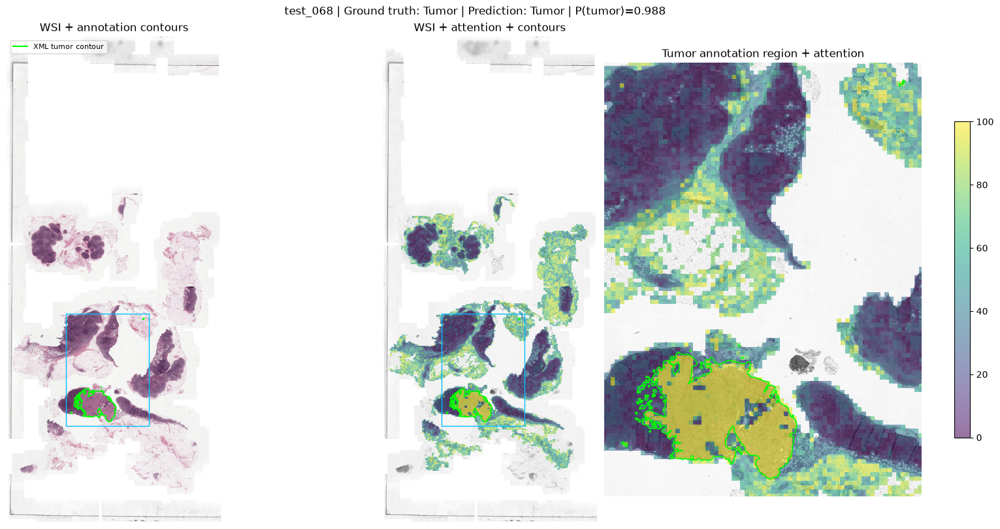

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


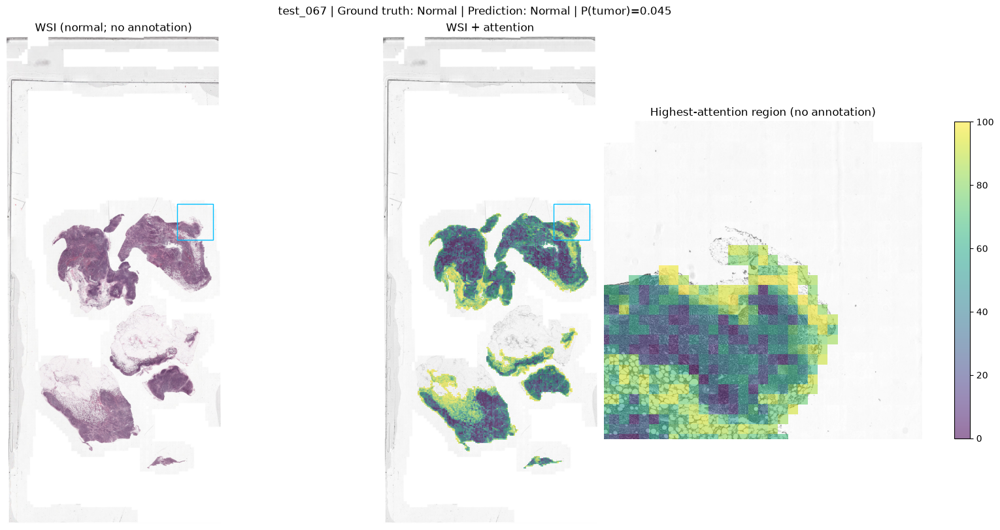

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)
===== C16 seed 0 =====


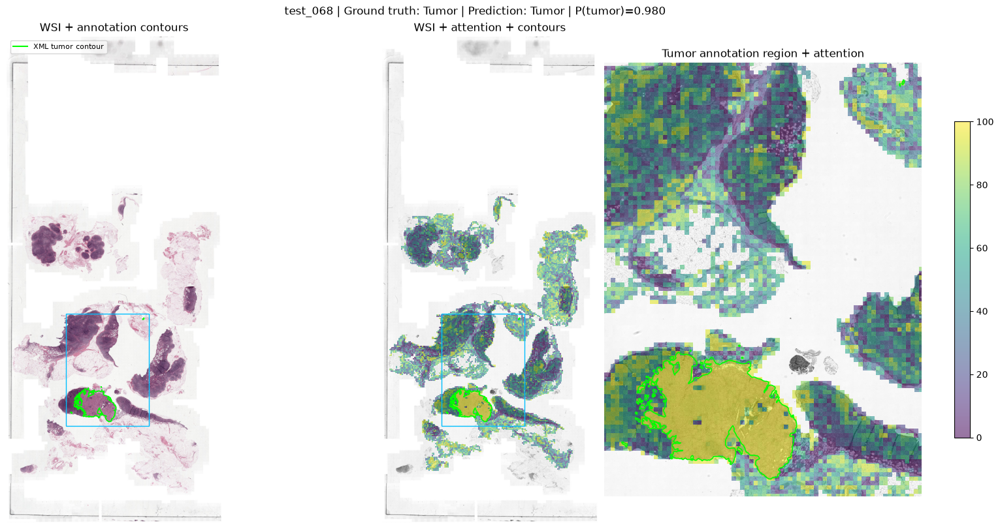

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


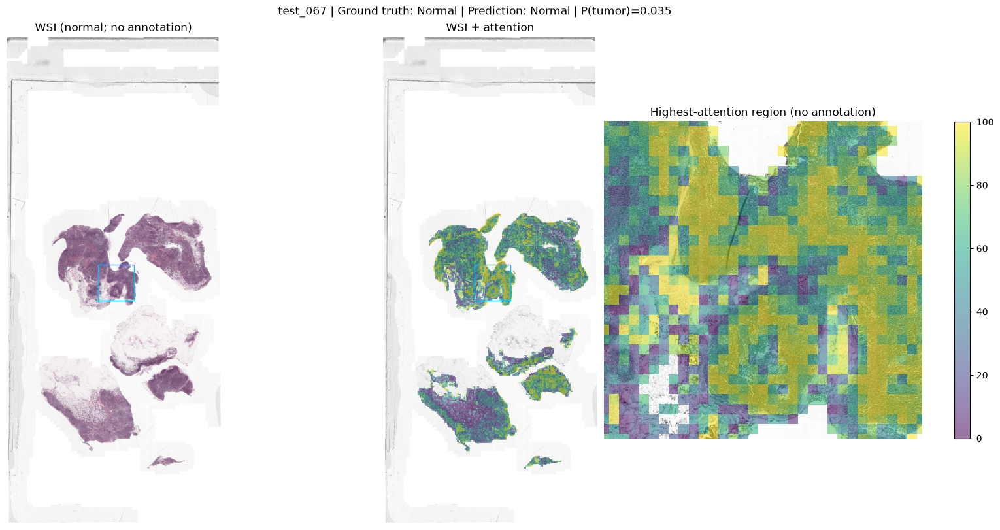

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)
===== C16 seed 1 =====


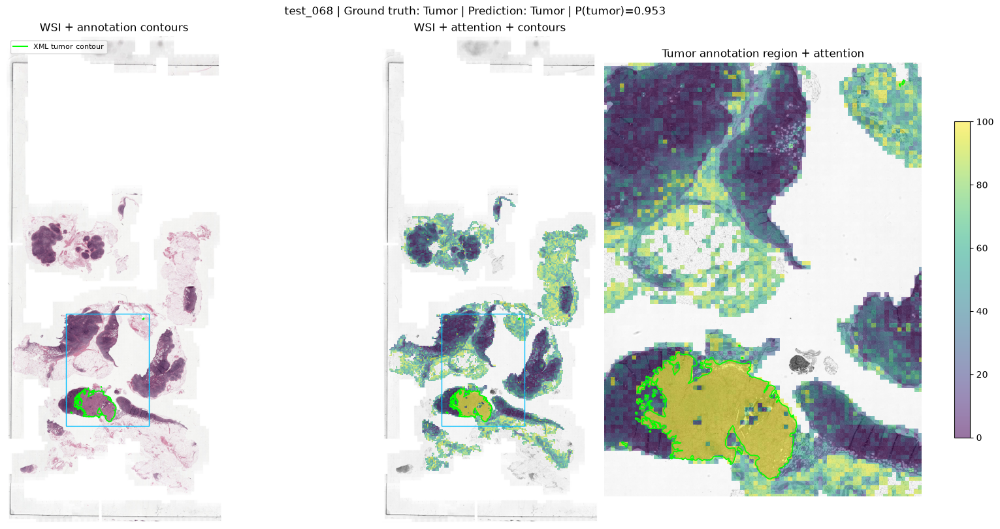

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


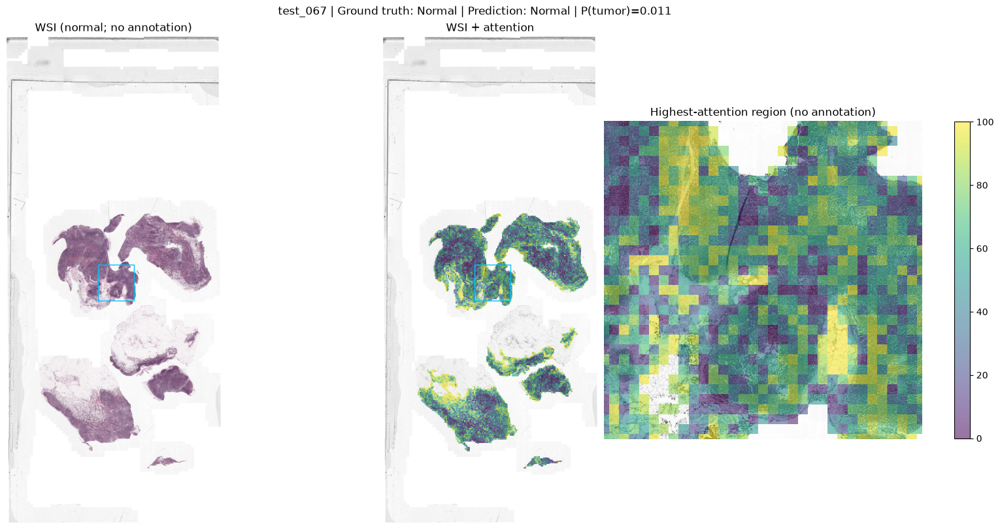

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)


In [13]:
from contextlib import contextmanager

ATTN_SEEDS = [42, 0, 1]


@contextmanager
def save_figures_on_show(paths):
    # visualize_wsi_attention calls plt.show() once per slide; save each figure just before it is shown.
    paths = iter(paths)
    original_show = plt.show
    def show(*args, **kwargs):
        plt.gcf().savefig(next(paths), dpi=200, bbox_inches='tight')
        original_show(*args, **kwargs)
    plt.show = show
    try:
        yield
    finally:
        plt.show = original_show


SLIDE_IDS = ('test_068', 'test_067')  # visualize_wsi_attention's default order
conf_c16 = load_config(os.path.join(PROJECT_DIR, 'config', CONFIG_FILES['C16']))
conf_c16.D_feat = infer_feature_dim(build_HDF5_feat_dataset(conf_c16.data_dir, conf_c16)[0])
c16_model = ABMIL(conf_c16).to(device)
for seed in ATTN_SEEDS:
    print(f'===== C16 seed {seed} =====')
    c16_state = torch.load(CKPT_DIR / f'C16_seed{seed}.pt', map_location=device)
    with save_figures_on_show([FIG_DIR / f'attention_{s}_seed{seed}.png' for s in SLIDE_IDS]):
        attention_visualizations = visualize_wsi_attention(
            c16_model, conf_c16, PROJECT_DIR, c16_state, slide_ids=SLIDE_IDS)

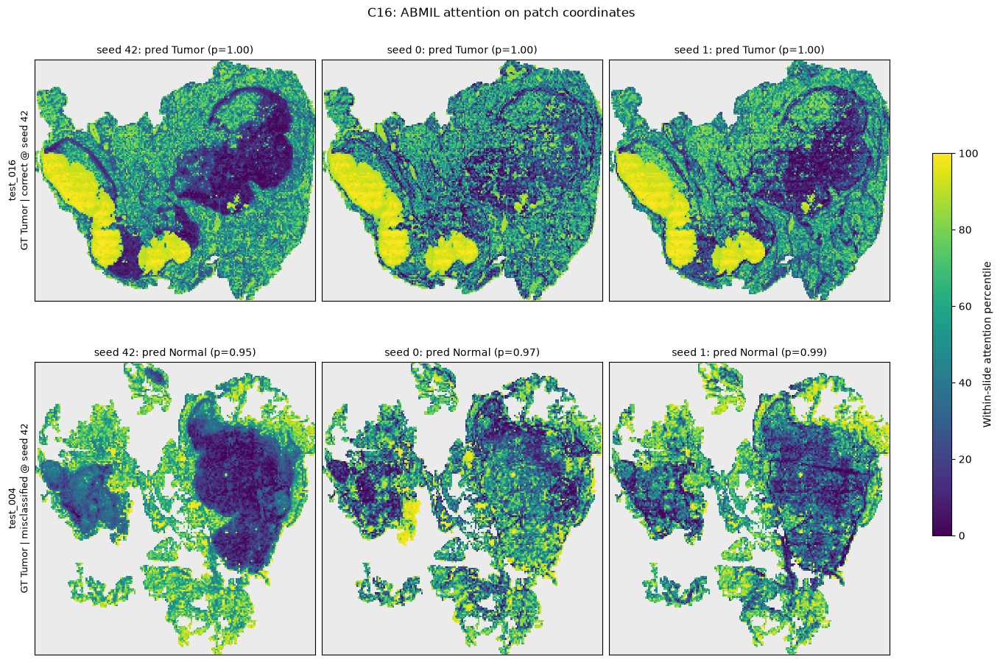

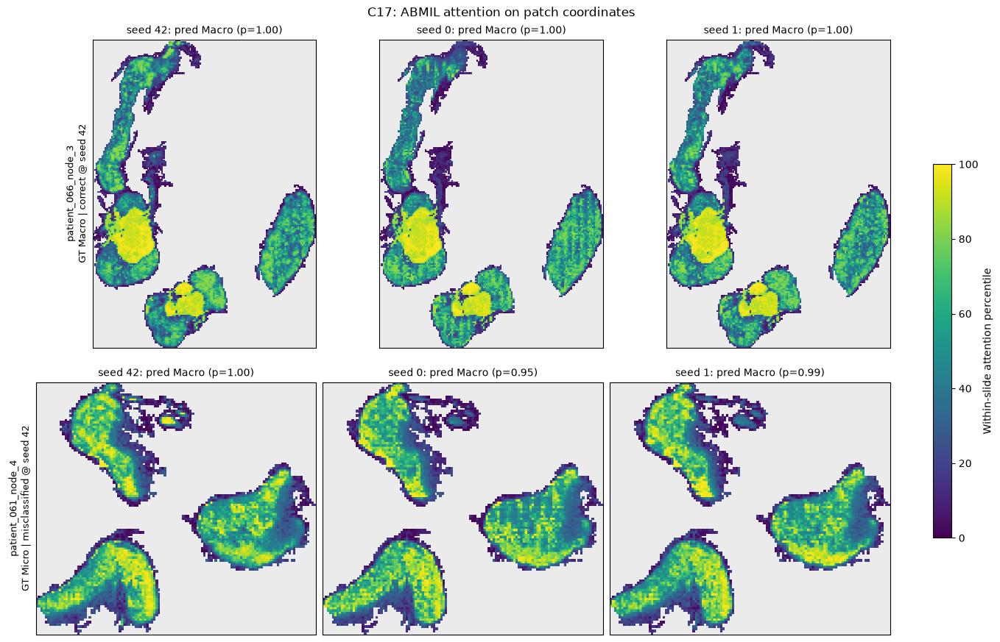

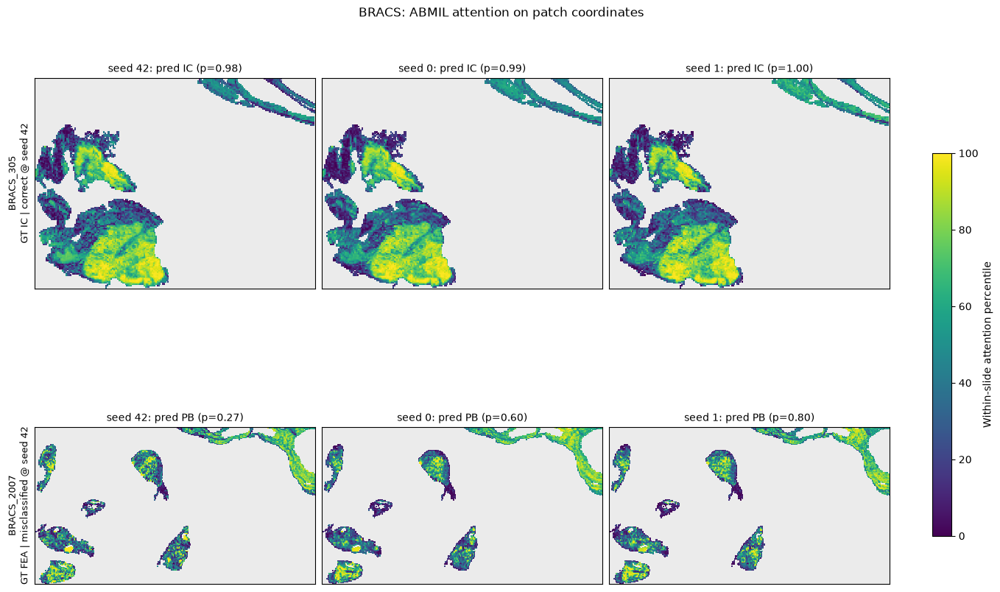

In [18]:
import h5py
import numpy as np
from PIL import Image
from matplotlib.colors import Normalize
from wsi_visualization import attention_percentiles, render_attention

ATTN_SEEDS = [42, 0, 1]
ATTN_REF_SEED = 42  # slides are picked from this seed's test predictions
# Label order of the supplied HDF5 files (C17: slide-level metastasis size; BRACS: 7 subtypes).
CLASS_NAMES = {
    'C16': ['Normal', 'Tumor'],
    'C17': ['Negative', 'ITC', 'Micro', 'Macro'],
    'BRACS': ['N', 'PB', 'UDH', 'FEA', 'ADH', 'DCIS', 'IC'],
}


def pick_slides(dataset, seed):
    preds = pd.read_csv(RESULTS_DIR / f'{dataset}_seed{seed}_test_predictions.csv')
    preds['p_true'] = [preds.at[i, f'prob_{label}'] for i, label in preds['label'].items()]
    correct = preds[preds.label == preds.pred]
    if (correct.label > 0).any():
        correct = correct[correct.label > 0]
    wrong = preds[preds.label != preds.pred]
    picks = []
    if len(correct):
        picks.append(('correct', correct.sort_values('p_true').iloc[-1]))
    if len(wrong):
        picks.append(('misclassified', wrong.sort_values('p_true').iloc[0]))
    return picks


@torch.no_grad()
def slide_attention(model, conf, slide_id):
    with h5py.File(conf.data_dir, 'r') as h5:
        features = torch.from_numpy(np.asarray(h5[slide_id]['feat'][:], dtype=np.float32))
        coords = np.asarray(h5[slide_id]['coords'][:], dtype=np.float64)
    model.eval()
    logits, attention = model(features.unsqueeze(0).to(device), return_attention=True)
    return coords, attention.cpu().numpy().reshape(-1), torch.softmax(logits, dim=-1)[0].cpu().numpy()


def attention_map(coords, weights, patch_size=512, max_px=800):
    # Blank canvas in level-0 coordinates; render_attention only uses its size.
    x0, y0 = coords.min(axis=0)
    x1, y1 = coords.max(axis=0) + patch_size
    scale = max_px / max(x1 - x0, y1 - y0)
    canvas = Image.new('L', (max(1, int(np.ceil((x1 - x0) * scale))), max(1, int(np.ceil((y1 - y0) * scale)))))
    extent = (x0, x1, y1, y0)
    return render_attention(canvas, extent, coords, attention_percentiles(weights), patch_size), extent


for ds in DATASETS:
    conf_ds = load_config(os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[ds]))
    picks = pick_slides(ds, ATTN_REF_SEED)
    with h5py.File(conf_ds.data_dir, 'r') as h5:
        conf_ds.D_feat = int(h5[picks[0][1].slide_id]['feat'].shape[1])
    names = CLASS_NAMES[ds]

    fig, axes = plt.subplots(len(picks), len(ATTN_SEEDS), figsize=(4.5 * len(ATTN_SEEDS), 4.5 * len(picks)),
                             squeeze=False, layout='constrained')
    for col, seed in enumerate(ATTN_SEEDS):
        model_ds = ABMIL(conf_ds).to(device)
        model_ds.load_state_dict(torch.load(CKPT_DIR / f'{ds}_seed{seed}.pt', map_location=device))
        for row, (kind, slide) in enumerate(picks):
            coords, weights, probabilities = slide_attention(model_ds, conf_ds, slide.slide_id)
            heat, extent = attention_map(coords, weights)
            ax = axes[row, col]
            artist = ax.imshow(heat, extent=extent, origin='upper', cmap='viridis',
                               norm=Normalize(0, 100), interpolation='nearest')
            ax.set_facecolor('0.92')
            ax.set_xticks([])
            ax.set_yticks([])
            pred = int(probabilities.argmax())
            ax.set_title(f'seed {seed}: pred {names[pred]} (p={probabilities[pred]:.2f})', fontsize=10)
            if col == 0:
                ax.set_ylabel(f'{slide.slide_id}\nGT {names[int(slide.label)]} | {kind} @ seed {ATTN_REF_SEED}',
                              fontsize=9)
    fig.colorbar(artist, ax=axes, shrink=0.6, label='Within-slide attention percentile')
    fig.suptitle(f'{ds}: ABMIL attention on patch coordinates')
    fig.savefig(FIG_DIR / f'attention_map_{ds}.png', dpi=200, bbox_inches='tight')
    plt.show()

# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.